In [1]:
import re
import math
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


class URLFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self):
        # Match IPv4 addresses used instead of domain names
        self.ip_pattern = re.compile(
            r"^(?:http[s]?://)?(?:www\.)?"
            r"(?:(?:25[0-5]|2[0-4][0-9]|[01]?[0-9][0-9]?)\.){3}"
            r"(?:25[0-5]|2[0-4][0-9]|[01]?[0-9][0-9]?)"
            r"(?:[:/]|$)"
        )
        # Special characters commonly inspected in phishing and malicious URLs
        self.special_chars = ["@", "?", "-", "=", ".", "_", "/", "%", "&"]

    @staticmethod
    def _shannon_entropy(text: str) -> float:
        # Compute Shannon entropy to measure character randomness
        if not text:
            return 0.0
        counts = Counter(text)
        length = len(text)
        return -sum((count / length) * math.log2(count / length) for count in counts.values())

    def _extract_single_url(self, raw_url: str) -> dict:
        u = str(raw_url).strip()
        has_https = 1 if u.lower().startswith("https://") else 0
        has_http = 1 if u.lower().startswith("http://") else 0

        # Prepend http:// temporarily when scheme is missing so urlparse extracts netloc properly
        parse_target = u if re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", u) else "http://" + u
        try:
            parsed = urlparse(parse_target)
            hostname = parsed.netloc.lower().split(":")[0]
            path = parsed.path
        except ValueError:
            # Fallback for malformed bracketed hosts that raise ValueError in urlparse
            without_scheme = re.sub(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", "", u)
            parts_slash = without_scheme.split("/", 1)
            hostname = parts_slash[0].lower().split(":")[0]
            path = "/" + parts_slash[1] if len(parts_slash) > 1 else ""

        has_ip = 1 if self.ip_pattern.match(u) else 0

        # Extract TLD and subdomain count for non-IP hostnames
        if has_ip or not hostname:
            tld = "ip_or_none"
            subdomain_count = 0
        else:
            parts = [p for p in hostname.split(".") if p]
            tld = parts[-1] if len(parts) > 1 else "unknown"
            subdomain_count = max(0, len(parts) - 2)

        digit_count = sum(c.isdigit() for c in u)
        letter_count = sum(c.isalpha() for c in u)

        features = {
            "url_length": len(u),
            "domain_length": len(hostname),
            "path_length": len(path),
            "url_entropy": self._shannon_entropy(u),
            "domain_entropy": self._shannon_entropy(hostname),
            "has_ip": has_ip,
            "has_https": has_https,
            "has_http": has_http,
            "digit_count": digit_count,
            "letter_count": letter_count,
            "digit_ratio": digit_count / max(1, len(u)),
            "subdomain_count": subdomain_count,
            "tld": tld,
        }

        # Use ASCII codes in column names to keep feature names clean and consistent
        for ch in self.special_chars:
            features[f"count_{ord(ch)}"] = u.count(ch)

        return features

    def fit(self, X, y=None):
        # Stateless feature extractor
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            urls = X.iloc[:, 0].astype(str)
        elif isinstance(X, pd.Series):
            urls = X.astype(str)
        else:
            urls = pd.Series(np.ravel(X)).astype(str)

        rows = [self._extract_single_url(u) for u in urls]
        return pd.DataFrame(rows, index=urls.index)


print("Setup and URLFeatureExtractor ready!")

Setup and URLFeatureExtractor ready!


In [2]:
import os
print(os.listdir())

['.config', 'url_preprocessing_pipeline.joblib', 'processed_url_splits.npz', 'Cleaned_ISCX_URL2016 (1).csv', 'sample_data']


In [3]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

plt.rcParams["figure.figsize"] = (7, 5)
sns.set_style("whitegrid")

In [4]:
data = np.load("processed_url_splits.npz", allow_pickle=True)
print("Keys inside npz:", data.files)

for k in data.files:
    print(f"Key '{k}' -> shape: {data[k].shape}, dtype: {data[k].dtype}")

pipeline = joblib.load("url_preprocessing_pipeline.joblib")
print("\nLoaded pipeline type:", type(pipeline))

Keys inside npz: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Key 'X_train' -> shape: (512900, 51), dtype: float64
Key 'X_test' -> shape: (128225, 51), dtype: float64
Key 'y_train' -> shape: (512900,), dtype: object
Key 'y_test' -> shape: (128225,), dtype: object
Key 'feature_names' -> shape: (51,), dtype: object

Loaded pipeline type: <class 'sklearn.pipeline.Pipeline'>


In [5]:
import numpy as np

data = np.load("processed_url_splits.npz", allow_pickle=True)
print("المفاتيح اللي جوه الملف:", data.files)

المفاتيح اللي جوه الملف: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']


In [6]:
data = np.load("processed_url_splits.npz", allow_pickle=True)
print("Keys inside npz:", data.files)

for k in data.files:
    print(f"Key '{k}' -> shape: {data[k].shape}, dtype: {data[k].dtype}")

pipeline = joblib.load("url_preprocessing_pipeline.joblib")
print("\nPipeline loaded successfully:", type(pipeline))

Keys inside npz: ['X_train', 'X_test', 'y_train', 'y_test', 'feature_names']
Key 'X_train' -> shape: (512900, 51), dtype: float64
Key 'X_test' -> shape: (128225, 51), dtype: float64
Key 'y_train' -> shape: (512900,), dtype: object
Key 'y_test' -> shape: (128225,), dtype: object
Key 'feature_names' -> shape: (51,), dtype: object

Pipeline loaded successfully: <class 'sklearn.pipeline.Pipeline'>


In [7]:
X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]
feature_names = data["feature_names"]

print("Unique labels in y_train:", np.unique(y_train))
print("Unique labels in y_test :", np.unique(y_test))
print("Any NaN in X_train?", np.isnan(X_train).any())
print("Any NaN in X_test ?", np.isnan(X_test).any())

Unique labels in y_train: ['benign' 'defacement' 'malware' 'phishing']
Unique labels in y_test : ['benign' 'defacement' 'malware' 'phishing']
Any NaN in X_train? False
Any NaN in X_test ? False


In [8]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)

print("Baseline Logistic Regression training & prediction completed!")

Baseline Logistic Regression training & prediction completed!


In [9]:
# Calculate overall accuracy
acc = accuracy_score(y_test, y_pred)

# Calculate macro-averaged metrics for multiclass classification
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

# Calculate specific metrics for the 'phishing' class
target_label = "phishing"
prec_phishing = precision_score(y_test, y_pred, labels=[target_label], average='macro', zero_division=0)
rec_phishing = recall_score(y_test, y_pred, labels=[target_label], average='macro', zero_division=0)
f1_phishing = f1_score(y_test, y_pred, labels=[target_label], average='macro', zero_division=0)

print(f"Overall Accuracy: {acc:.4f}")
print(f"Macro Precision : {prec_macro:.4f}")
print(f"Macro Recall    : {rec_macro:.4f}")
print(f"Macro F1-Score  : {f1_macro:.4f}")

print(f"\n--- Metrics for class '{target_label}' ---")
print(f"Precision       : {prec_phishing:.4f}")
print(f"Recall          : {rec_phishing:.4f}")
print(f"F1-Score        : {f1_phishing:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, zero_division=0))

Overall Accuracy: 0.8465
Macro Precision : 0.8071
Macro Recall    : 0.7300
Macro F1-Score  : 0.7471

--- Metrics for class 'phishing' ---
Precision       : 0.5972
Recall          : 0.2449
F1-Score        : 0.3474

--- Classification Report ---
              precision    recall  f1-score   support

      benign       0.86      0.96      0.91     85616
  defacement       0.84      0.94      0.89     19062
     malware       0.92      0.77      0.84      4729
    phishing       0.60      0.24      0.35     18818

    accuracy                           0.85    128225
   macro avg       0.81      0.73      0.75    128225
weighted avg       0.82      0.85      0.82    128225



In [10]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy          : {acc:.4f}")
print(f"Weighted Precision: {prec:.4f}")
print(f"Weighted Recall   : {rec:.4f}")
print(f"Weighted F1-Score : {f1:.4f}")

print("\n--- Detailed Classification Report per Class ---")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy          : 0.8465
Weighted Precision: 0.8241
Weighted Recall   : 0.8465
Weighted F1-Score : 0.8221

--- Detailed Classification Report per Class ---
              precision    recall  f1-score   support

      benign       0.86      0.96      0.91     85616
  defacement       0.84      0.94      0.89     19062
     malware       0.92      0.77      0.84      4729
    phishing       0.60      0.24      0.35     18818

    accuracy                           0.85    128225
   macro avg       0.81      0.73      0.75    128225
weighted avg       0.82      0.85      0.82    128225



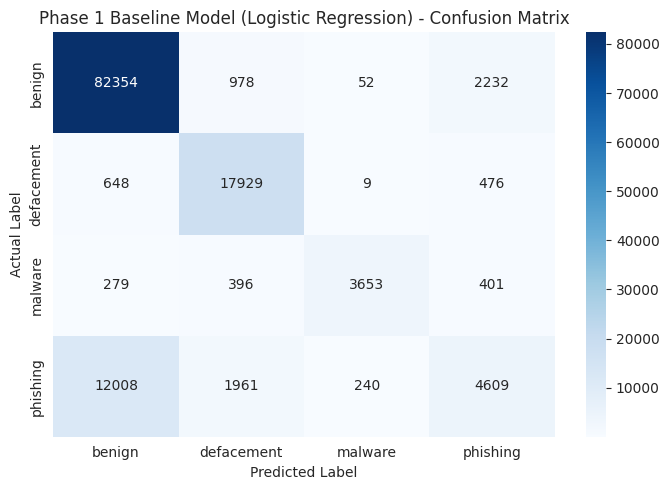

In [11]:
labels_order = ['benign', 'defacement', 'malware', 'phishing']
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_order,
    yticklabels=labels_order
)
plt.title("Phase 1 Baseline Model (Logistic Regression) - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Performance Metrics Interpretation (Phase 1)

* **Why we rely on Recall and F1-Score rather than Accuracy alone:**
  Although overall **Accuracy** reached **0.8465**, relying on Accuracy alone can be misleading in phishing URL detection because `benign` represents the largest share of the dataset (85,616 samples in the test set), whereas for the `phishing` class the baseline model achieved a **Recall** of only **0.24** (detecting 4,609 out of 18,818 phishing URLs, while 12,008 phishing URLs were misclassified as `benign`).
* In security-sensitive environments such as banking or user protection, missing even a single phishing URL (**False Negative**) can lead to credential theft or account compromise and carries a much higher cost than flagging a legitimate link (**False Positive**).
* Therefore, we prioritize **Recall** to capture as many malicious links as possible and **F1-Score** (**0.35** for `phishing` and **0.8221** weighted average) to balance precision and recall for **Phase 1**.